# 🇮🇩 Indonesian KTP Data Augmentation Pipeline

This notebook applies a standardized, deterministic augmentation pipeline to expand our training dataset across the Doc-PAD classes:
- **`real_ktp`** (Real physical card captures)
- **`fake_screen`** (Screen replay attacks)
- **`fake_print`** (Paper / cardstock printout attacks)
- **`fake_template`** (Synthetic generator samples - capped at **10 samples** to avoid dataset imbalance)
- **`other`** (Non-KTP cards: SIM, credit cards, driver licenses, receipts, etc. for hard-negative rejection)

---

### 🎯 Augmentation Yield: 1 Image $\rightarrow$ 35 Variants
For every single source image, this pipeline generates exactly **35 augmented variations**:
1. **Brightness (5 variations)**: 5 exposure factors ranging from dark to high illumination (-60% to +50%).
2. **Blur (5 variations)**: 5 Gaussian blur kernel levels (subtle to heavy motion/defocus blur).
3. **Rotation (10 variations)**: 10 tilt angles (both clockwise and counter-clockwise from $\pm 1^\circ$ to $\pm 15^\circ$).
4. **Center Crop (5 variations)**: 5 zoom/crop scales (95% down to 75% center crop, resized back to standard dimensions).
5. **Monochrome (5 copies)**: 5 copies of the grayscale converted image (simulates photocopies & monochrome sensors).
6. **Contrast (5 variations)**: 5 dynamic contrast multipliers (low contrast / washed-out to high contrast / saturated).

> 💡 **Ready for Data Collection**: You can run the visual demo cell immediately on `fake_template` images. When you return with captured photos for `real_ktp`, `fake_screen`, and `fake_print`, simply drop them into `datasets/processed/<class_name>/` and run Cell 7.

## Cell 1: Environment Setup & Imports

In [1]:
import os
import sys
import io
from pathlib import Path
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Ensure clean display in notebook
%matplotlib inline

print("✅ Setup complete. OpenCV version:", cv2.__version__)
print("✅ Current working directory:", os.getcwd())

✅ Setup complete. OpenCV version: 4.13.0
✅ Current working directory: c:\Users\veiro\Documents\research\ekyc\notebooks


## Cell 2: Pipeline Configuration & Directory Mapping
Defines input source directories, output destination, augmentation ranges, and sample limits.

In [2]:
# Base Paths (Relative to /notebooks folder)
BASE_INPUT_DIR = Path("../datasets/processed").resolve()
BASE_OUTPUT_DIR = Path("../datasets/augmented").resolve()

# Destination Mode:
# True  -> Appends augmented images directly into datasets/processed/<class>/ alongside originals
# False -> Saves into separate datasets/augmented/<class>/ directory
SAVE_DIRECTLY_TO_PROCESSED = True

# Target Classes and their folder mapping (with aliases)
CLASS_MAPPING = {
    "real_ktp": {"source": "real_ktp", "limit": None},          # Process ALL real captures
    "fake_screen": {"source": "fake_screen", "limit": None},      # Process ALL screen captures
    "fake_print": {"source": "fake_print", "limit": None},        # Process ALL print captures
    "fake_template": {"source": "fake_template", "limit": 10},   # Strictly capped at 10 samples!
    "other": {"source": "other", "limit": None},                  # Non-KTP cards (SIM, ATM, receipts, etc.)
}

# --- Augmentation Parameters ---
# 1. Brightness Multipliers (5 variations)
BRIGHTNESS_FACTORS = [0.4, 0.6, 0.8, 1.25, 1.5]

# 2. Gaussian Blur Kernels (5 variations)
BLUR_KERNELS = [(3, 3), (5, 5), (7, 7), (11, 11), (15, 15)]

# 3. Rotation Angles in Degrees (10 variations)
ROTATION_ANGLES = [-15, -10, -6, -3, -1, 1, 3, 6, 10, 15]

# 4. Center Crop Scales (5 variations: 95% to 75% zoom)
CROP_SCALES = [0.95, 0.90, 0.85, 0.80, 0.75]

# 5. Monochrome Copies (5 copies)
MONOCHROME_COPIES = 5

# 6. Contrast Multipliers (5 variations)
CONTRAST_FACTORS = [0.5, 0.75, 1.25, 1.5, 1.8]

print(f"📁 Input base directory : {BASE_INPUT_DIR}")
print(f"💾 Output base directory: {BASE_OUTPUT_DIR}")
print(f"🎯 Augmentations per image: {len(BRIGHTNESS_FACTORS)} bright + {len(BLUR_KERNELS)} blur + {len(ROTATION_ANGLES)} rot + {len(CROP_SCALES)} crop + {MONOCHROME_COPIES} mono + {len(CONTRAST_FACTORS)} contrast = 35 total")

📁 Input base directory : C:\Users\veiro\Documents\research\ekyc\datasets\processed
💾 Output base directory: C:\Users\veiro\Documents\research\ekyc\datasets\augmented
🎯 Augmentations per image: 5 bright + 5 blur + 10 rot + 5 crop + 5 mono + 5 contrast = 35 total


## Cell 3: Augmentation Transformation Functions
Defines the 6 standalone transformation functions and the master generator that returns a dictionary of labeled images.

In [3]:
def augment_brightness(img_bgr: np.ndarray, factor: float) -> np.ndarray:
    """Adjust brightness by scaling RGB values."""
    scaled = img_bgr.astype(np.float32) * factor
    return np.clip(scaled, 0, 255).astype(np.uint8)


def augment_blur(img_bgr: np.ndarray, ksize: tuple) -> np.ndarray:
    """Apply Gaussian blur with given kernel size."""
    return cv2.GaussianBlur(img_bgr, ksize, 0)


def augment_rotation(img_bgr: np.ndarray, angle: float) -> np.ndarray:
    """Rotate image around center using border reflection to avoid black corners."""
    h, w = img_bgr.shape[:2]
    center = (w / 2.0, h / 2.0)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    return cv2.warpAffine(img_bgr, M, (w, h), borderMode=cv2.BORDER_REFLECT_101)


def augment_center_crop(img_bgr: np.ndarray, scale: float) -> np.ndarray:
    """Center crop by scale factor and resize back to original dimensions."""
    h, w = img_bgr.shape[:2]
    crop_w, crop_h = int(w * scale), int(h * scale)
    x1 = (w - crop_w) // 2
    y1 = (h - crop_h) // 2
    cropped = img_bgr[y1:y1 + crop_h, x1:x1 + crop_w]
    return cv2.resize(cropped, (w, h), interpolation=cv2.INTER_LINEAR)


def augment_monochrome(img_bgr: np.ndarray) -> np.ndarray:
    """Convert image to 3-channel grayscale / monochrome."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)


def augment_contrast(img_bgr: np.ndarray, factor: float) -> np.ndarray:
    """Adjust contrast centered around midpoint luminance (128)."""
    adjusted = 128.0 + factor * (img_bgr.astype(np.float32) - 128.0)
    return np.clip(adjusted, 0, 255).astype(np.uint8)


def generate_35_augmentations(img_bgr: np.ndarray) -> list[tuple[str, np.ndarray]]:
    """
    Master generator: takes 1 BGR image and returns a list of 35 tuples:
    [(suffix, transformed_img), ...]
    """
    results = []

    # 1. Brightness (5)
    for i, factor in enumerate(BRIGHTNESS_FACTORS, 1):
        results.append((f"bright_{i:02d}_factor{factor:.2f}", augment_brightness(img_bgr, factor)))

    # 2. Blur (5)
    for i, k in enumerate(BLUR_KERNELS, 1):
        results.append((f"blur_{i:02d}_k{k[0]}x{k[1]}", augment_blur(img_bgr, k)))

    # 3. Rotation (10)
    for i, angle in enumerate(ROTATION_ANGLES, 1):
        sign = "p" if angle >= 0 else "m"
        results.append((f"rot_{i:02d}_deg{sign}{abs(angle)}", augment_rotation(img_bgr, angle)))

    # 4. Center Crop (5)
    for i, scale in enumerate(CROP_SCALES, 1):
        results.append((f"crop_{i:02d}_scale{scale:.2f}", augment_center_crop(img_bgr, scale)))

    # 5. Monochrome (5 copies)
    mono_img = augment_monochrome(img_bgr)
    for i in range(1, MONOCHROME_COPIES + 1):
        results.append((f"mono_{i:02d}", mono_img.copy()))

    # 6. Contrast (5)
    for i, factor in enumerate(CONTRAST_FACTORS, 1):
        results.append((f"contrast_{i:02d}_factor{factor:.2f}", augment_contrast(img_bgr, factor)))

    return results


def get_next_id(folder: Path) -> int:
    """Find the highest numeric ID in folder like 0014_real_ktp.jpeg -> returns 15."""
    ids = []
    if folder.exists():
        for f in folder.iterdir():
            if f.is_file() and not f.name.endswith('.json'):
                prefix = f.stem.split('_')[0]
                if prefix.isdigit():
                    ids.append(int(prefix))
    return max(ids) + 1 if ids else 1

print("✅ Augmentation functions and ID tracker registered successfully!")

✅ Augmentation functions and ID tracker registered successfully!


## Cell 4: Visual Demonstration on a Single Sample
Tests all 35 variations on a sample KTP from `fake_template` and plots them in structured categories.

🖼️ Loading sample image for visual verification: 0001_fake_template.png
✅ Successfully generated 35 augmented variants!


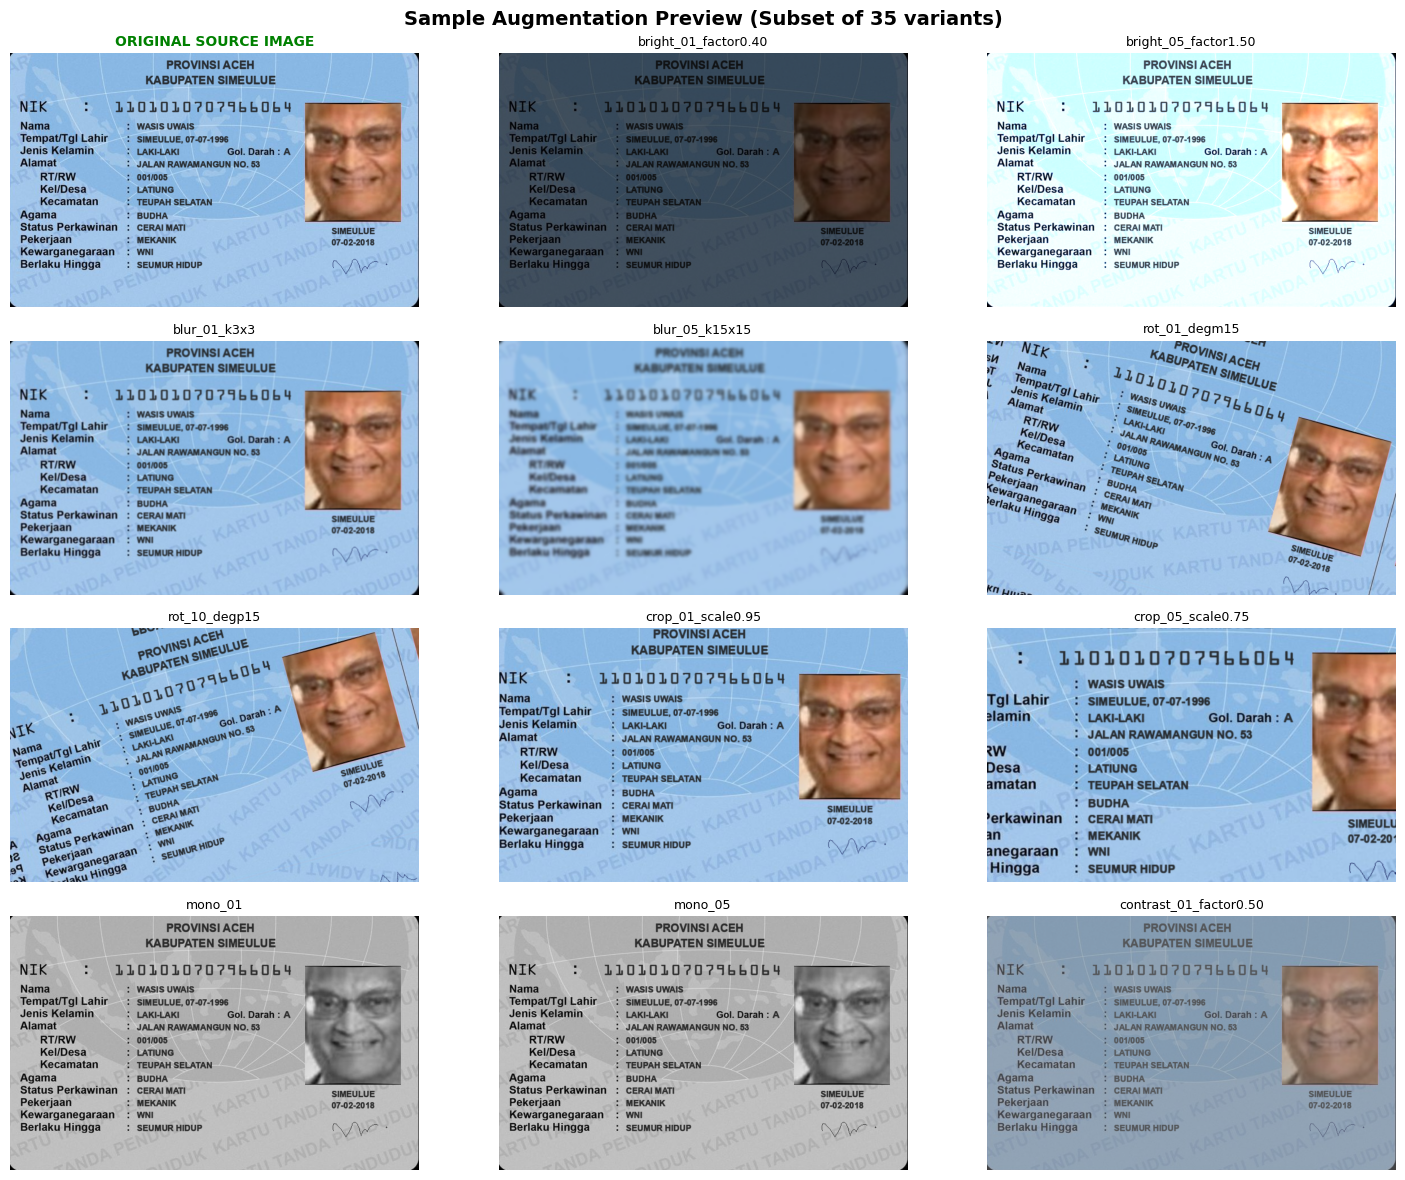

In [4]:
# Find a sample image from fake_template to demonstrate
template_dir = BASE_INPUT_DIR / "fake_template"
sample_files = list(template_dir.glob("*.png"))

if not sample_files:
    print("⚠️ No sample files found in fake_template. Please run notebook 02 first to export sample images.")
else:
    sample_path = sample_files[0]
    print(f"🖼️ Loading sample image for visual verification: {sample_path.name}")
    
    demo_bgr = cv2.imread(str(sample_path))
    demo_rgb = cv2.cvtColor(demo_bgr, cv2.COLOR_BGR2RGB)
    
    augmented_demo = generate_35_augmentations(demo_bgr)
    print(f"✅ Successfully generated {len(augmented_demo)} augmented variants!")
    
    # Visual Grid: Show Original + Selection of Augmentations
    # Pick 2 from each category (Original + 12 samples = 13 images total)
    showcase_indices = [0, 4, 5, 9, 10, 19, 20, 24, 25, 29, 30, 34]
    
    fig, axes = plt.subplots(4, 3, figsize=(15, 12))
    axes = axes.flatten()
    
    # 1. Original in first tile
    axes[0].imshow(demo_rgb)
    axes[0].set_title("ORIGINAL SOURCE IMAGE", fontsize=10, fontweight="bold", color="green")
    axes[0].axis("off")
    
    for plot_idx, aug_idx in enumerate(showcase_indices[:-1], 1):
        suffix, aug_bgr = augmented_demo[aug_idx]
        aug_rgb = cv2.cvtColor(aug_bgr, cv2.COLOR_BGR2RGB)
        axes[plot_idx].imshow(aug_rgb)
        axes[plot_idx].set_title(suffix, fontsize=9)
        axes[plot_idx].axis("off")
        
    plt.suptitle("Sample Augmentation Preview (Subset of 35 variants)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

## Cell 5: Source Datasets Inspection & Status Check
Scans `datasets/processed/` and displays how many images are ready for augmentation in each class.

In [5]:
print("=" * 75)
print("📊 DATASET INVENTORY CHECK (datasets/processed/)")
print("=" * 75)

inventory = {}
for target_class, info in CLASS_MAPPING.items():
    folder = BASE_INPUT_DIR / info["source"]
    folder.mkdir(parents=True, exist_ok=True)
    
    # Find all supported image formats
    images = list(folder.glob("*.png")) + list(folder.glob("*.jpg")) + list(folder.glob("*.jpeg"))
    count = len(images)
    limit = info["limit"]
    
    to_process = min(count, limit) if limit else count
    expected_augmented = to_process * 35
    start_id = get_next_id(folder)
    end_id = start_id + expected_augmented - 1 if expected_augmented > 0 else start_id
    
    inventory[target_class] = {
        "found": count,
        "to_process": to_process,
        "expected_yield": expected_augmented,
        "start_id": start_id,
        "end_id": end_id,
        "images": images,
    }
    
    status_icon = "✅ Ready" if count > 0 else "⏳ Waiting for capture data"
    rule_note = f"[Capped at {limit}]" if limit else "[All images]"
    id_range_str = f"[IDs: {start_id:04d} -> {end_id:04d}]" if expected_augmented > 0 else "[No new IDs]"
    
    print(f"{target_class:<15} : {count:>5} found -> Augment {to_process:>4} {rule_note:<18} -> Yield: {expected_augmented:>5} imgs {id_range_str:<22} | {status_icon}")

total_expected = sum(item["expected_yield"] for item in inventory.values())
print("=" * 75)
print(f"Total projected augmented images across all classes: {total_expected:,}")
print("=" * 75)

📊 DATASET INVENTORY CHECK (datasets/processed/)
real_ktp        :    14 found -> Augment   14 [All images]       -> Yield:   490 imgs [IDs: 0015 -> 0504]    | ✅ Ready
fake_screen     :    29 found -> Augment   29 [All images]       -> Yield:  1015 imgs [IDs: 0030 -> 1044]    | ✅ Ready
fake_print      :    16 found -> Augment   16 [All images]       -> Yield:   560 imgs [IDs: 0017 -> 0576]    | ✅ Ready
fake_template   :  2000 found -> Augment   10 [Capped at 10]     -> Yield:   350 imgs [IDs: 2001 -> 2350]    | ✅ Ready
other           :    14 found -> Augment   14 [All images]       -> Yield:   490 imgs [IDs: 0015 -> 0504]    | ✅ Ready
Total projected augmented images across all classes: 2,905


## Cell 6: Execute Batch Augmentation Pipeline
Applies the 35 variations to images in each class.

### 🏷️ Naming Pattern:
- Every augmented file follows the exact same template: **`<id>_<class>.png`**
- IDs continue sequentially from the **last existing ID** currently in the folder (e.g. `0015_real_ktp.png`, `0030_fake_screen.png`).
- Full traceability is saved in **`augmentation_manifest.json`** inside each class folder.
- For `fake_template`: Processes exactly **10 samples**.
- For `real_ktp`, `fake_screen`, `fake_print`, `other`: Processes all images in those folders.

In [6]:
import json

print("=" * 75)
print("🚀 STARTING BATCH AUGMENTATION PIPELINE (SEQUENTIAL ID CONTINUATION)")
print("=" * 75)

execution_summary = {}

for target_class, data in inventory.items():
    target_dir = (BASE_INPUT_DIR / target_class) if SAVE_DIRECTLY_TO_PROCESSED else (BASE_OUTPUT_DIR / target_class)
    target_dir.mkdir(parents=True, exist_ok=True)
    
    images = data["images"]
    limit = CLASS_MAPPING[target_class]["limit"]
    
    if not images:
        print(f"\n⏩ Skipping '{target_class}': No source images found yet in {target_dir.name}/")
        execution_summary[target_class] = 0
        continue
        
    selected_images = images[:limit] if limit else images
    next_id = get_next_id(target_dir)
    start_id = next_id
    
    print(f"\n⚙️ Processing '{target_class}': {len(selected_images)} source image(s)")
    print(f"   Destination : {target_dir}")
    print(f"   Starting ID : {next_id:04d}_{target_class}.png")
    
    class_saved_count = 0
    manifest = {}
    
    # If manifest already exists from previous runs, load it
    manifest_path = target_dir / "augmentation_manifest.json"
    if manifest_path.exists():
        try:
            with open(manifest_path, "r", encoding="utf-8") as mf:
                manifest = json.load(mf)
        except Exception:
            manifest = {}
            
    for img_path in tqdm(selected_images, desc=f"Augmenting {target_class}"):
        img_bgr = cv2.imread(str(img_path))
        
        if img_bgr is None:
            print(f"   ⚠️ Could not read: {img_path.name}")
            continue
            
        # Generate all 35 variations
        variants = generate_35_augmentations(img_bgr)
        
        for suffix, aug_img in variants:
            out_filename = f"{next_id:04d}_{target_class}.png"
            out_path = target_dir / out_filename
            cv2.imwrite(str(out_path), aug_img)
            
            manifest[out_filename] = {
                "source_image": img_path.name,
                "augmentation": suffix,
            }
            next_id += 1
            class_saved_count += 1
            
    # Save manifest for full traceability
    with open(manifest_path, "w", encoding="utf-8") as mf:
        json.dump(manifest, mf, indent=2)
        
    end_id = next_id - 1
    execution_summary[target_class] = class_saved_count
    print(f"   💾 Generated {class_saved_count} new images: {start_id:04d}_{target_class}.png -> {end_id:04d}_{target_class}.png")
    print(f"   📋 Manifest updated at: {manifest_path.name}")

print("\n" + "=" * 75)
print("🎉 BATCH AUGMENTATION COMPLETE!")
print("=" * 75)

🚀 STARTING BATCH AUGMENTATION PIPELINE (SEQUENTIAL ID CONTINUATION)

⚙️ Processing 'real_ktp': 14 source image(s)
   Destination : C:\Users\veiro\Documents\research\ekyc\datasets\processed\real_ktp
   Starting ID : 0015_real_ktp.png


Augmenting real_ktp:   0%|          | 0/14 [00:00<?, ?it/s]

   💾 Generated 490 new images: 0015_real_ktp.png -> 0504_real_ktp.png
   📋 Manifest updated at: augmentation_manifest.json

⚙️ Processing 'fake_screen': 29 source image(s)
   Destination : C:\Users\veiro\Documents\research\ekyc\datasets\processed\fake_screen
   Starting ID : 0030_fake_screen.png


Augmenting fake_screen:   0%|          | 0/29 [00:00<?, ?it/s]

   💾 Generated 1015 new images: 0030_fake_screen.png -> 1044_fake_screen.png
   📋 Manifest updated at: augmentation_manifest.json

⚙️ Processing 'fake_print': 16 source image(s)
   Destination : C:\Users\veiro\Documents\research\ekyc\datasets\processed\fake_print
   Starting ID : 0017_fake_print.png


Augmenting fake_print:   0%|          | 0/16 [00:00<?, ?it/s]

   💾 Generated 560 new images: 0017_fake_print.png -> 0576_fake_print.png
   📋 Manifest updated at: augmentation_manifest.json

⚙️ Processing 'fake_template': 10 source image(s)
   Destination : C:\Users\veiro\Documents\research\ekyc\datasets\processed\fake_template
   Starting ID : 2001_fake_template.png


Augmenting fake_template:   0%|          | 0/10 [00:00<?, ?it/s]

   💾 Generated 350 new images: 2001_fake_template.png -> 2350_fake_template.png
   📋 Manifest updated at: augmentation_manifest.json

⚙️ Processing 'other': 14 source image(s)
   Destination : C:\Users\veiro\Documents\research\ekyc\datasets\processed\other
   Starting ID : 0015_other.png


Augmenting other:   0%|          | 0/14 [00:00<?, ?it/s]

   💾 Generated 490 new images: 0015_other.png -> 0504_other.png
   📋 Manifest updated at: augmentation_manifest.json

🎉 BATCH AUGMENTATION COMPLETE!


## Cell 7: Final Audit & Visual Verification
Audits the dataset folders on disk, counts total files, and plots samples of the augmented results.

📁 FINAL DATASET AUDIT (processed/)
real_ktp        :   504 files on disk | Range: 0001_real_ktp.jpeg -> 0504_real_ktp.png
fake_screen     :  1044 files on disk | Range: 0001_fake_screen.jpeg -> 1044_fake_screen.png
fake_print      :   576 files on disk | Range: 0001_fake_print.jpeg -> 0576_fake_print.png
fake_template   :  2350 files on disk | Range: 0001_fake_template.png -> 2350_fake_template.png
other           :   504 files on disk | Range: 0001_other.jpeg -> 0504_other.png
---------------------------------------------------------------------------
Total Dataset Size across all classes: 4,978 images


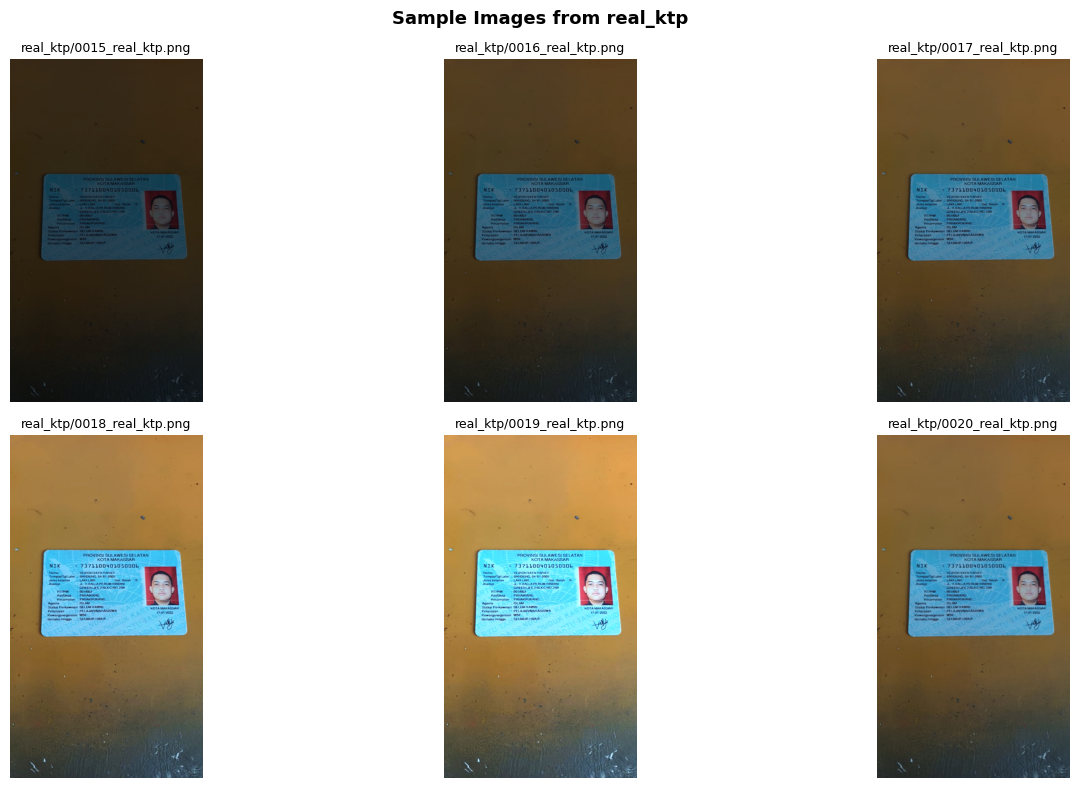

In [7]:
print("=" * 75)
active_base = BASE_INPUT_DIR if SAVE_DIRECTLY_TO_PROCESSED else BASE_OUTPUT_DIR
print(f"📁 FINAL DATASET AUDIT ({active_base.name}/)")
print("=" * 75)

total_files = 0
for target_class in CLASS_MAPPING.keys():
    dir_path = active_base / target_class
    if dir_path.exists():
        files = sorted([f for f in dir_path.iterdir() if f.is_file() and not f.name.endswith('.json')])
        count = len(files)
        total_files += count
        first_f = files[0].name if files else "None"
        last_f = files[-1].name if files else "None"
        print(f"{target_class:<15} : {count:>5} files on disk | Range: {first_f} -> {last_f}")
    else:
        print(f"{target_class:<15} :     0 files (folder not created yet)")

print("-" * 75)
print(f"Total Dataset Size across all classes: {total_files:,} images")
print("=" * 75)

# Render samples from any active class
active_dirs = [active_base / c for c in CLASS_MAPPING.keys() if (active_base / c).exists() and list((active_base / c).glob("*.png"))]

if active_dirs:
    sample_dir = active_dirs[0]
    sample_images = list(sample_dir.glob("*.png"))[:6]
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()
    
    for i, p in enumerate(sample_images):
        bgr = cv2.imread(str(p))
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        axes[i].imshow(rgb)
        axes[i].set_title(f"{p.parent.name}/{p.name}", fontsize=9)
        axes[i].axis("off")
        
    plt.suptitle(f"Sample Images from {sample_dir.name}", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("ℹ️ No images found to display.")